In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay


In [2]:
# load the pharmacy sales dataset
df = pd.read_csv("global_pharmacy_sales_2020_2025_daily_dataset.csv")

# display the first five rows
display(df.head())

# display dataset information
print("dataset shape:", df.shape)
print("column names:", df.columns.tolist())


,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0


dataset shape: (177990, 14)
column names: ['date', 'year', 'month', 'day', 'region', 'country', 'category', 'medicine', 'age_group', 'units_sold', 'unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag']


In [3]:
# create high and low demand classes using median sales
median_sales = df["units_sold"].median()

df["demand_class"] = np.where(
    df["units_sold"] >= median_sales,
    "high demand",
    "low demand"
)

# display the target distribution
print(df["demand_class"].value_counts())


demand_class
high demand    89217
low demand     88773
Name: count, dtype: int64


In [4]:
# select numerical features for classification
features = [
    "unit_price",
    "stock_level",
    "expiry_days_remaining",
    "month",
    "covid_flag"
]

# select a sample to reduce training time
data = df.sample(n=min(12000, len(df)), random_state=42)

# separate features and target
X = data[features]
y = data["demand_class"]

# replace infinite values with missing values
X = X.replace([np.inf, -np.inf], np.nan)

# remove rows where every selected feature is missing
valid_rows = X.notna().any(axis=1)
X = X.loc[valid_rows]
y = y.loc[valid_rows]

# split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("training records:", len(X_train))
print("testing records:", len(X_test))


training records: 9600
testing records: 2400


In [5]:
# create pipelines for all four classifiers
models = {
    "logistic regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),

    "decision tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(
            max_depth=10,
            random_state=42
        ))
    ]),

    "svm": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", C=1.0))
    ]),

    "knn": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ])
}

print("four baseline classifiers are ready")


four baseline classifiers are ready


In [6]:
# store the evaluation results
results = []
trained_models = {}

# train and evaluate each classifier
for name, model in models.items():
    start_time = time.perf_counter()
    model.fit(X_train, y_train)
    train_time = time.perf_counter() - start_time
    start_time = time.perf_counter()
    y_pred = model.predict(X_test)
    predict_time = time.perf_counter() - start_time

    # calculate classification metrics
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "f1_score": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "training_time_sec": train_time,
        "prediction_time_sec": predict_time
    })

    trained_models[name] = model

# display the comparative results
results_df = pd.DataFrame(results)
display(results_df.round(4))


,model,accuracy,precision,recall,f1_score,training_time_sec,prediction_time_sec
0,logistic regression,0.8462,0.8469,0.8463,0.8462,0.0537,0.0017
1,decision tree,0.8429,0.8429,0.8429,0.8429,0.0377,0.0022
2,svm,0.8500,0.8505,0.8501,0.8500,1.1912,0.4320
3,knn,0.8346,0.8346,0.8346,0.8346,0.0360,0.0197


In [7]:
# compare models using three-fold cross-validation
cv_results = []

for name, model in models.items():
    start_time = time.perf_counter()

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=3,
        scoring="f1_macro",
        n_jobs=-1
    )

    elapsed_time = time.perf_counter() - start_time

    cv_results.append({
        "model": name,
        "mean_cv_f1": scores.mean(),
        "std_cv_f1": scores.std(),
        "cv_time_sec": elapsed_time
    })

cv_df = pd.DataFrame(cv_results)

# display average performance and variation
display(cv_df.round(4))


,model,mean_cv_f1,std_cv_f1,cv_time_sec
0,logistic regression,0.8402,0.0042,3.9380
1,decision tree,0.8248,0.0116,3.4977
2,svm,0.8483,0.0055,4.9175
3,knn,0.8243,0.0082,3.4429


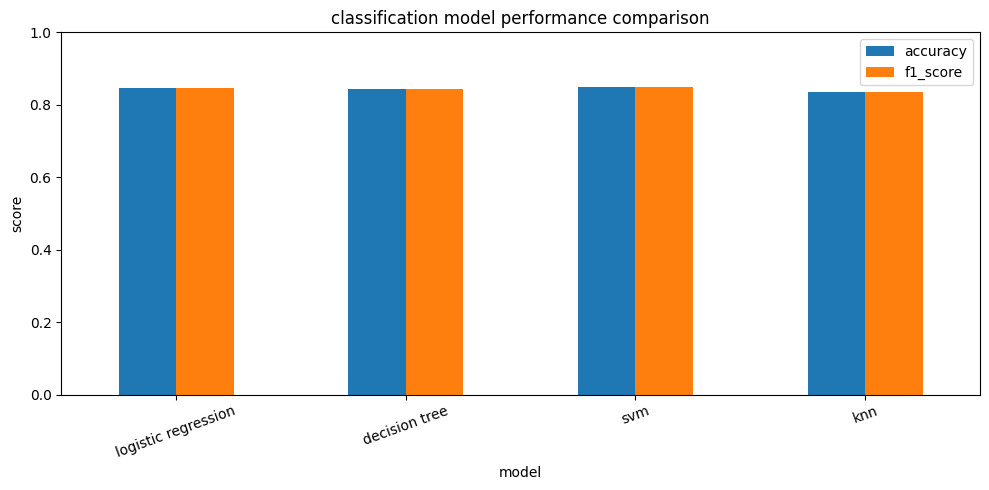

In [8]:
# compare accuracy and f1-score across models
plot_data = results_df.set_index("model")[
    ["accuracy", "f1_score"]
]

plot_data.plot(kind="bar", figsize=(10, 5))

plt.title("classification model performance comparison")
plt.ylabel("score")
plt.xlabel("model")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.show()


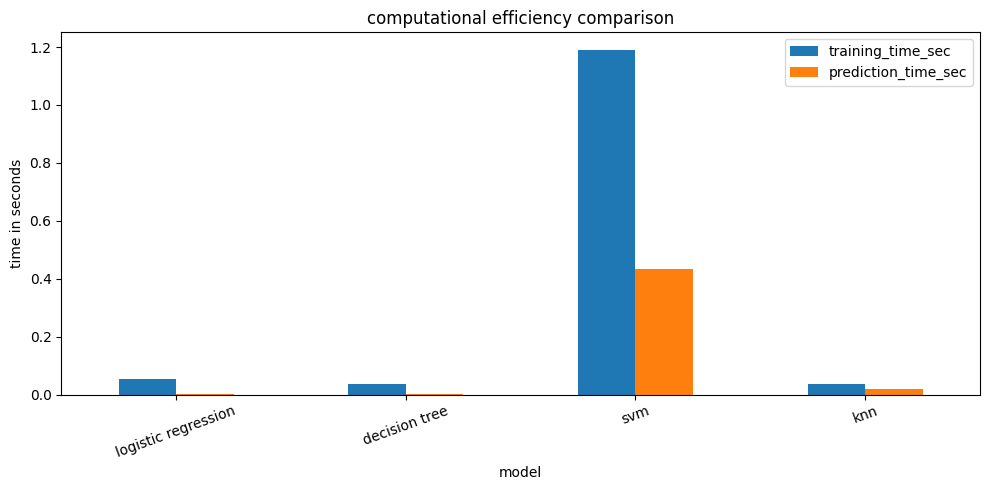

In [9]:
# compare training and prediction times
time_data = results_df.set_index("model")[
    ["training_time_sec", "prediction_time_sec"]
]

time_data.plot(kind="bar", figsize=(10, 5))

plt.title("computational efficiency comparison")
plt.ylabel("time in seconds")
plt.xlabel("model")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


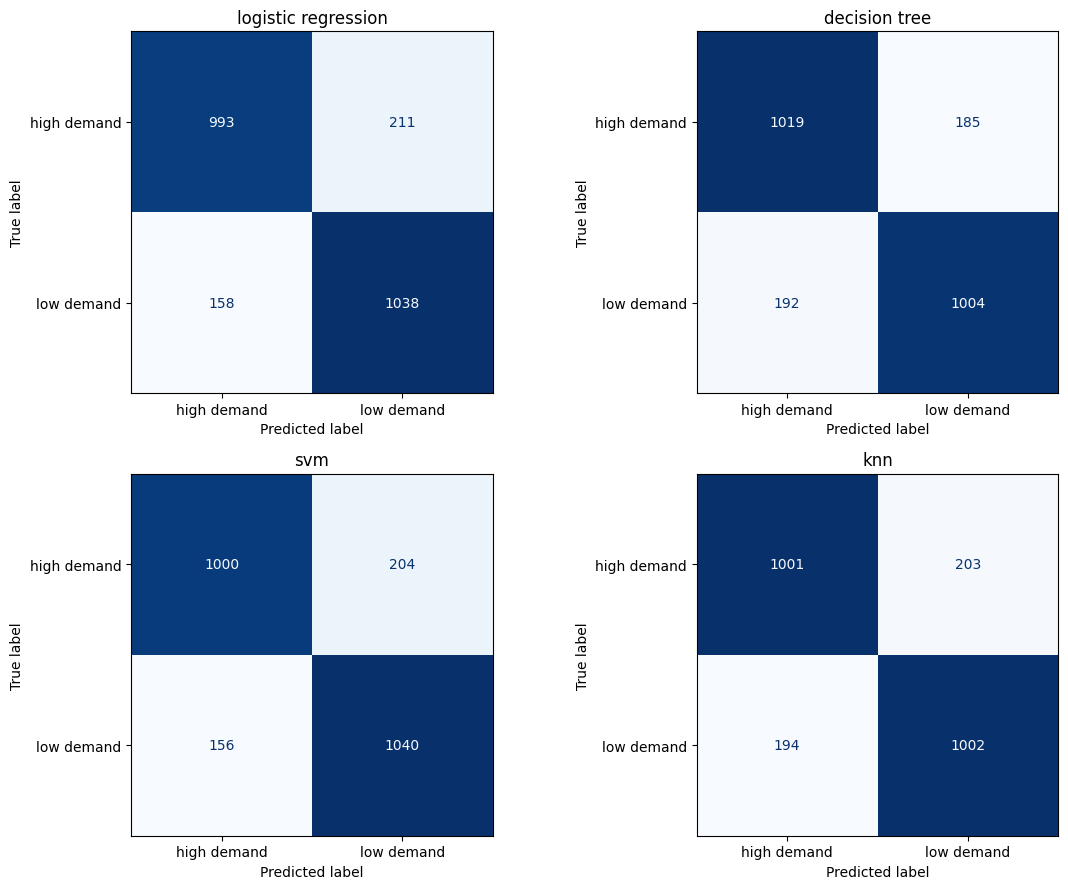

In [10]:
# compare actual and predicted classes for each model
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (name, model) in zip(axes.flatten(), trained_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()


In [12]:

# display detailed metrics for each classifier
for name, model in trained_models.items():
    print("\nmodel:", name)

    predictions = model.predict(X_test)

    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))



model: logistic regression
              precision    recall  f1-score   support

 high demand       0.86      0.82      0.84      1204
  low demand       0.83      0.87      0.85      1196

    accuracy                           0.85      2400
   macro avg       0.85      0.85      0.85      2400
weighted avg       0.85      0.85      0.85      2400


model: decision tree
              precision    recall  f1-score   support

 high demand       0.84      0.85      0.84      1204
  low demand       0.84      0.84      0.84      1196

    accuracy                           0.84      2400
   macro avg       0.84      0.84      0.84      2400
weighted avg       0.84      0.84      0.84      2400


model: svm
              precision    recall  f1-score   support

 high demand       0.87      0.83      0.85      1204
  low demand       0.84      0.87      0.85      1196

    accuracy                           0.85      2400
   macro avg       0.85      0.85      0.85      2400
weighted avg

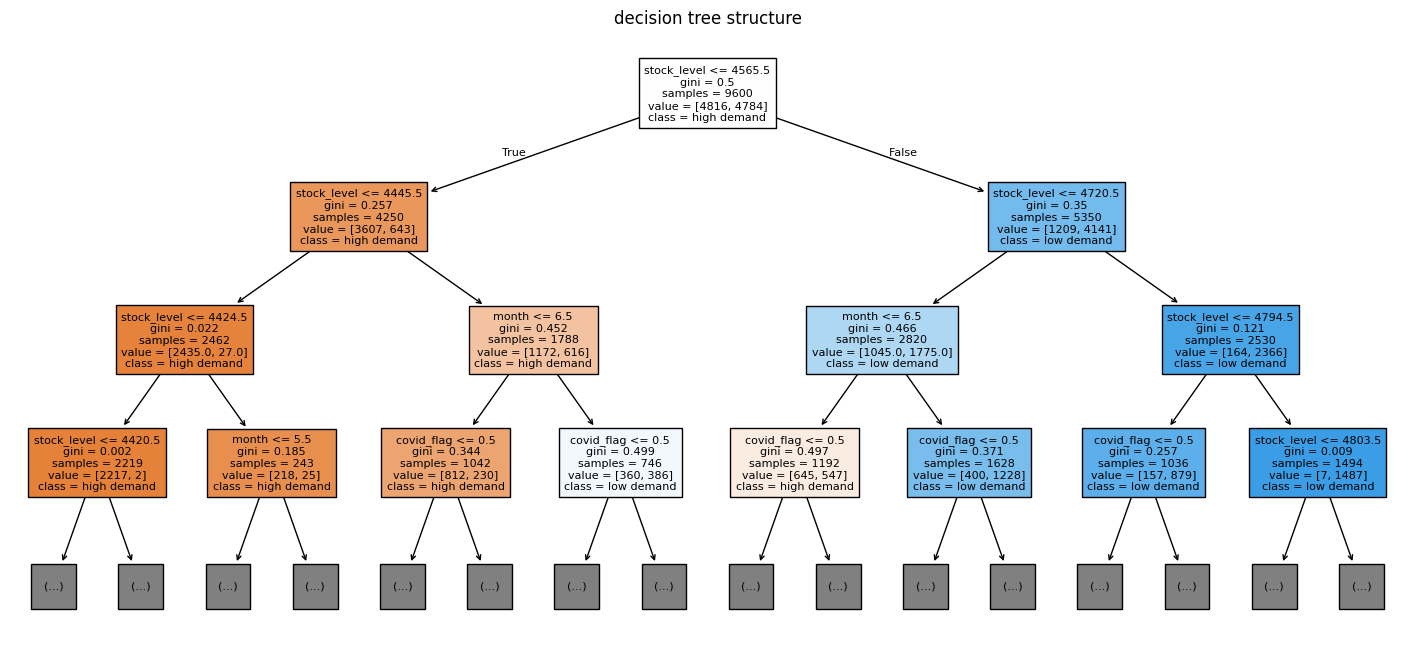

In [13]:
from sklearn.tree import plot_tree

# extract the trained decision tree
tree_model = trained_models["decision tree"].named_steps["model"]

# display the tree structure
plt.figure(figsize=(18, 8))

plot_tree(
    tree_model,
    feature_names=features,
    class_names=tree_model.classes_,
    filled=True,
    max_depth=3,
    fontsize=8
)

plt.title("decision tree structure")
plt.show()


In [14]:
# rank models by macro f1-score
ranked_models = results_df.sort_values(
    by="f1_score",
    ascending=False
)

display(ranked_models[
    ["model", "accuracy", "precision", "recall",
     "f1_score", "training_time_sec", "prediction_time_sec"]
].round(4))

best_name = ranked_models.iloc[0]["model"]

print("best baseline by test macro f1-score:", best_name)


,model,accuracy,precision,recall,f1_score,training_time_sec,prediction_time_sec
2,svm,0.8500,0.8505,0.8501,0.8500,1.1912,0.4320
0,logistic regression,0.8462,0.8469,0.8463,0.8462,0.0537,0.0017
1,decision tree,0.8429,0.8429,0.8429,0.8429,0.0377,0.0022
3,knn,0.8346,0.8346,0.8346,0.8346,0.0360,0.0197


best baseline by test macro f1-score: svm


In [15]:
# print a concise summary of the comparison
fastest_training = results_df.loc[
    results_df["training_time_sec"].idxmin(), "model"
]

fastest_prediction = results_df.loc[
    results_df["prediction_time_sec"].idxmin(), "model"
]

print("comparative analysis completed")
print("best macro f1 model:", best_name)
print("fastest training model:", fastest_training)
print("fastest prediction model:", fastest_prediction)
print("use the metrics and plots to select the most suitable model")


comparative analysis completed
best macro f1 model: svm
fastest training model: knn
fastest prediction model: logistic regression
use the metrics and plots to select the most suitable model
